# Evidencia clase 14/10/26

Dada una transferencia $T(z)$ definida por sus coeficientes $b$ (numerador) y $a$ (denominador):

$$T(z) = \frac{b_0 + b_1 z^{-1} + \dots + b_M z^{-M}}{a_0 + a_1 z^{-1} + \dots + a_N z^{-N}}$$

queremos visualizar su respuesta en frecuencia: módulo $|T(e^{j\omega})|$ y fase $\angle T(e^{j\omega})$.

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

## Función para graficar módulo y fase

`signal.freqz(b, a, worN, fs)` evalúa $T(z)$ sobre la circunferencia unitaria $z = e^{j\omega}$ y devuelve las frecuencias y la respuesta compleja $H$. De ahí:
- Módulo en dB: $20 \log_{10}|H|$
- Fase: `np.unwrap(np.angle(H))` (desenrollada para evitar saltos de $2\pi$)

In [51]:
def plot_respuesta(b, a, fs=2, N=2048, titulo='T(z)'):
    """Grafica módulo (dB) y fase de T(z) = B(z)/A(z).
    Con fs=2 el eje queda normalizado a Nyquist (0 a 1)."""
    w, H = signal.freqz(b, a, worN=N, fs=fs)

    modulo_db = 20 * np.log10(np.abs(H) + 1e-15)  # +eps para evitar log(0)
    fase = np.unwrap(np.angle(H))

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

    ax1.plot(w, modulo_db)
    ax1.set_ylabel('|T| [dB]')
    ax1.set_title(f'Respuesta en frecuencia de {titulo}')
    ax1.grid(True, which='both')

    ax2.plot(w, fase)
    ax2.set_ylabel('Fase [rad]')
    ax2.set_xlabel('Frecuencia normalizada (× π rad/muestra)' if fs == 2 else 'Frecuencia [Hz]')
    ax2.grid(True, which='both')

    plt.tight_layout()
    plt.show()

    return w, H

## Ejemplo 1: FIR — promediador móvil de 5 muestras

$T(z) = \frac{1}{5}(1 + z^{-1} + z^{-2} + z^{-3} + z^{-4})$, o sea $b = [1,1,1,1,1]/5$, $a = [1]$. Es un pasabajos con fase lineal.

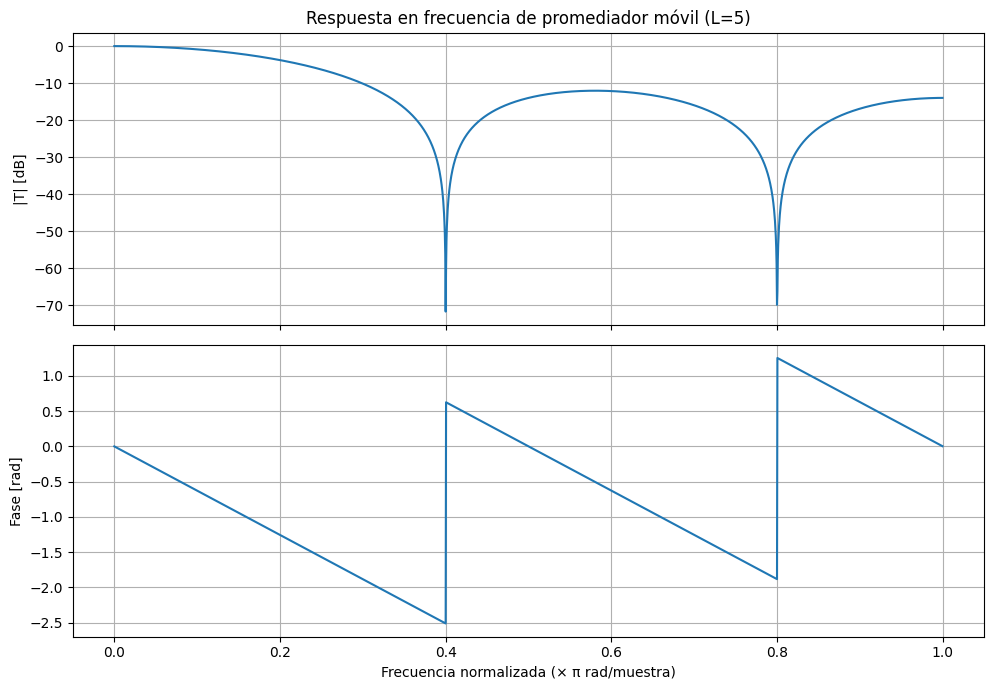

In [52]:
b = np.ones(5) / 5
a = [1]

w, H = plot_respuesta(b, a, titulo='promediador móvil (L=5)')

## Ejemplo 2: IIR de primer orden

$T(z) = \frac{1 - \alpha}{1 - \alpha z^{-1}}$ con $\alpha = 0.9$, o sea $b = [1-\alpha]$, $a = [1, -\alpha]$. Pasabajos con ganancia unitaria en continua y fase no lineal.

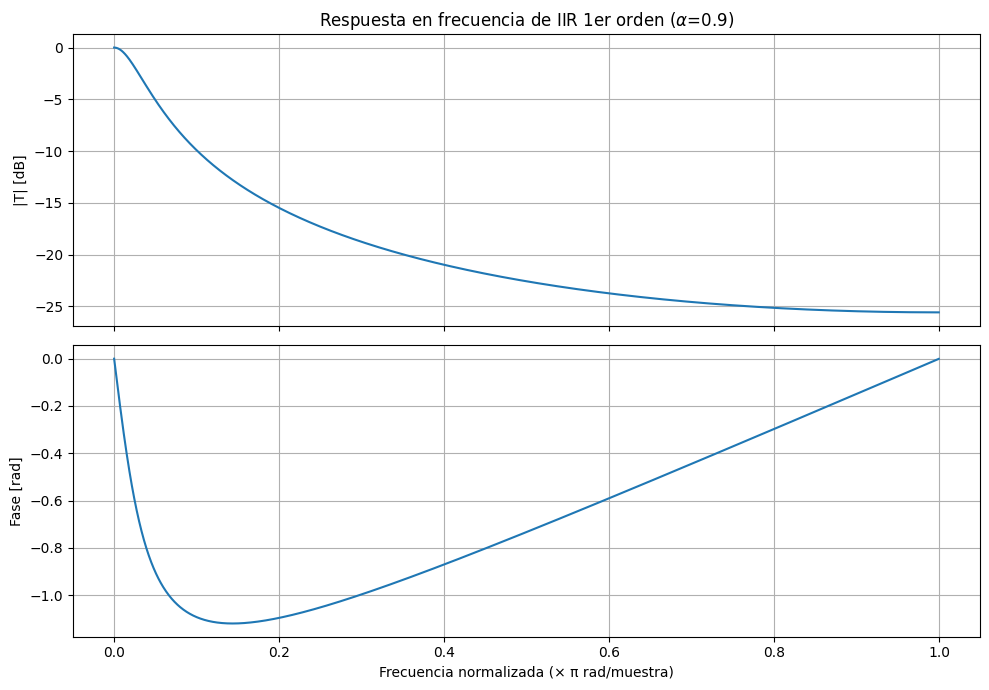

In [53]:
alpha = 0.9
b = [1 - alpha]
a = [1, -alpha]

w, H = plot_respuesta(b, a, titulo=r'IIR 1er orden ($\alpha$=0.9)')

## Ejemplo 3: con frecuencia de muestreo real

Pasando `fs` el eje queda en Hz. Uso un Butterworth de orden 4 con corte en 1 kHz para $f_s = 8$ kHz.

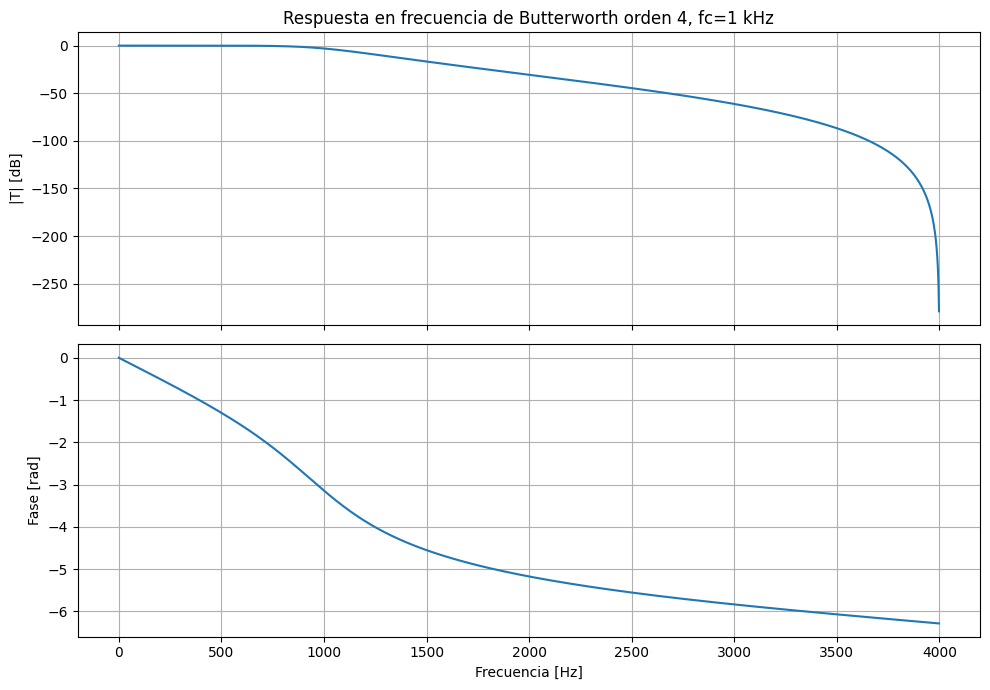

In [54]:
fs = 8000
b, a = signal.butter(4, 1000, btype='low', fs=fs)

w, H = plot_respuesta(b, a, fs=fs, titulo='Butterworth orden 4, fc=1 kHz')

## Ejemplo 4: FIR con $h(n) = (1, 1, 1)$

En un FIR los coeficientes del numerador **son** la respuesta al impulso: $b_k = h(k)$, y el denominador es $a = [1]$ (sin realimentación). Entonces:

$$T(z) = \sum_n h(n)\, z^{-n} = 1 + z^{-1} + z^{-2} \quad\Rightarrow\quad b = [1, 1, 1],\ a = [1]$$

Es el promediador de 3 muestras sin normalizar (ganancia 3 en continua ≈ 9.54 dB). Sus ceros son las raíces de $z^2 + z + 1$, o sea $z = e^{\pm j 2\pi/3}$, por lo que el módulo se anula en $\omega = 2\pi/3$ (0.667 en el eje normalizado). La fase es lineal ($-\omega$, retardo de 1 muestra) con un salto de $\pi$ en ese cero.

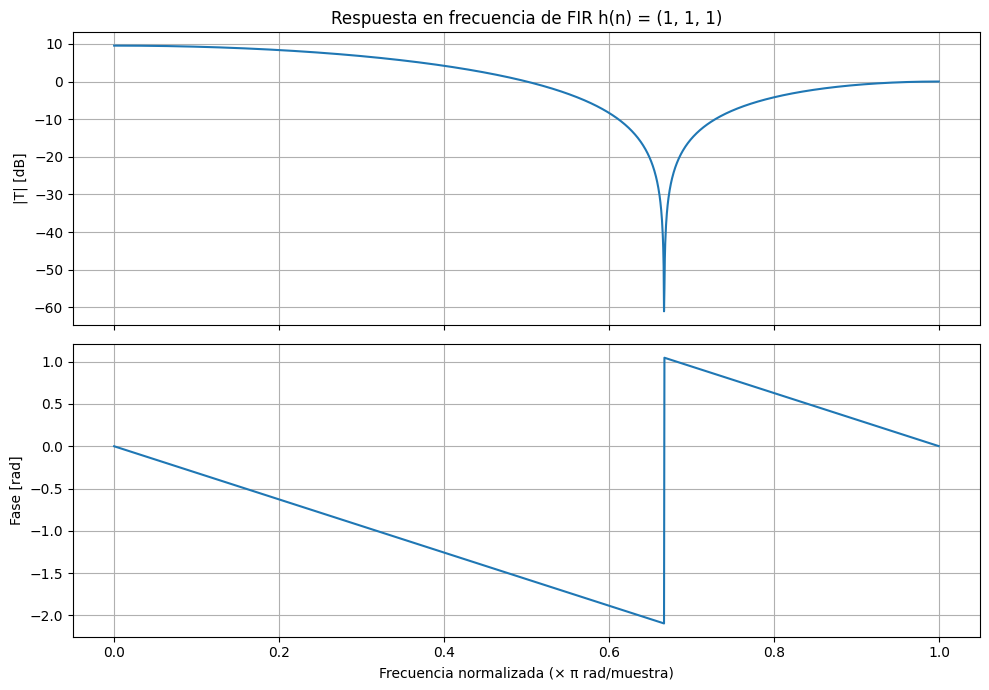

In [55]:
h = np.array([1, 1, 1], dtype=float)
b = h       # FIR: los coeficientes b son las muestras de h(n)
a = [1]     # sin polos (salvo en z=0)

w, H = plot_respuesta(b, a, titulo='FIR h(n) = (1, 1, 1)')

Verifico que esos $b$ y $a$ efectivamente responden a $h(n) = (1,1,1)$: filtro una delta y miro la salida.

h(n) = [1. 1. 1. 0. 0. 0. 0. 0.]
ceros: [-0.5+0.8660254j -0.5-0.8660254j] -> |z| = [1. 1.] , ángulo/π = [ 0.66666667 -0.66666667]


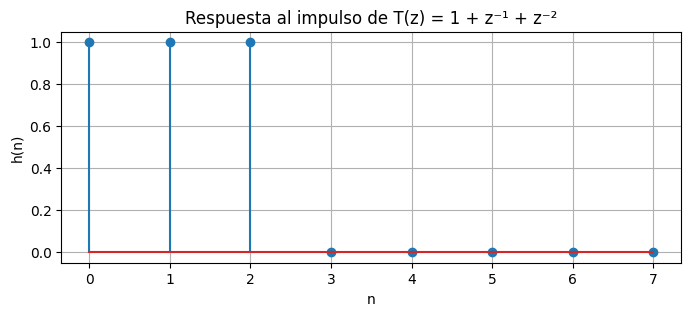

In [56]:
delta = np.zeros(8)
delta[0] = 1
h_obtenida = signal.lfilter(b, a, delta)
print('h(n) =', h_obtenida)
print('ceros:', np.roots(b), '-> |z| =', np.abs(np.roots(b)), ', ángulo/π =', np.angle(np.roots(b)) / np.pi)

plt.figure(figsize=(8, 3))
plt.stem(np.arange(len(delta)), h_obtenida)
plt.xlabel('n')
plt.ylabel('h(n)')
plt.title('Respuesta al impulso de T(z) = 1 + z⁻¹ + z⁻²')
plt.grid(True)
plt.show()

## Ejemplo 5: diseño con `iirdesign` y análisis con `freqz` / `freqs`

- `signal.iirdesign(wp, ws, gpass, gstop, ftype)` **diseña** un IIR a partir de una plantilla: borde de banda de paso `wp`, borde de banda de rechazo `ws`, máxima atenuación en la banda de paso `gpass` [dB] y mínima atenuación en la de rechazo `gstop` [dB]. Devuelve `b, a`.
- `signal.freqz(b, a)` evalúa una transferencia **digital** $T(z)$ en $z = e^{j\omega}$.
- `signal.freqs(b, a)` evalúa una transferencia **analógica** $T(s)$ en $s = j\Omega$ (frecuencias en rad/s).

Plantilla: pasabajos con paso hasta 1 kHz (≤ 1 dB) y rechazo desde 1.5 kHz (≥ 40 dB), $f_s = 8$ kHz.

Orden digital: 12


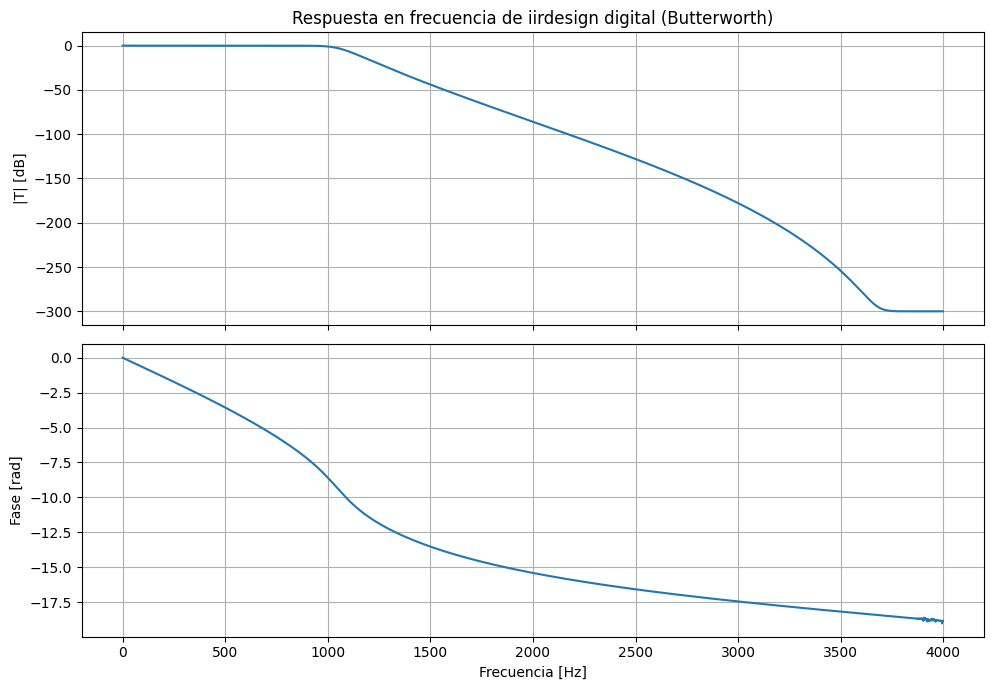

In [57]:
fs = 8000
fp, fstop = 1000, 1500   # [Hz]
gpass, gstop = 1, 40     # [dB]

# Digital: iirdesign + freqz
b_d, a_d = signal.iirdesign(fp, fstop, gpass, gstop, ftype='butter', fs=fs)
print('Orden digital:', len(a_d) - 1)
w, H = plot_respuesta(b_d, a_d, fs=fs, titulo='iirdesign digital (Butterworth)')

Orden analógico: 14


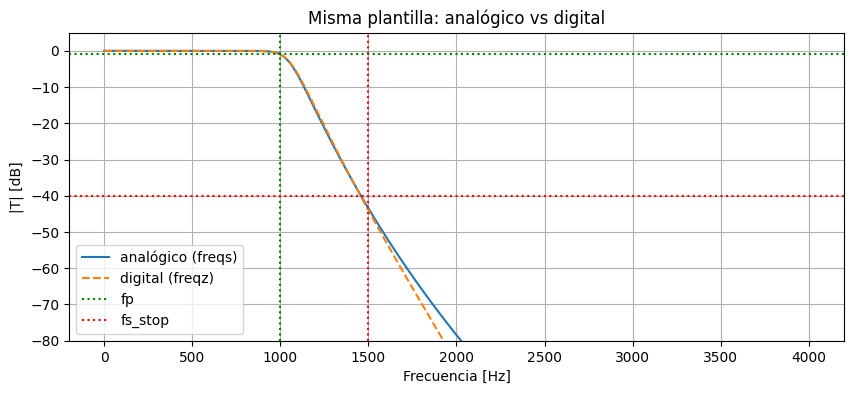

In [58]:
# Analógico: iirdesign(analog=True) + freqs (frecuencias en rad/s)
b_s, a_s = signal.iirdesign(2*np.pi*fp, 2*np.pi*fstop, gpass, gstop, ftype='butter', analog=True)
print('Orden analógico:', len(a_s) - 1)

f = np.linspace(1, fs/2, 2048)                  # [Hz]
_, H_s = signal.freqs(b_s, a_s, worN=2*np.pi*f)  # freqs trabaja en rad/s
_, H_z = signal.freqz(b_d, a_d, worN=f, fs=fs)

plt.figure(figsize=(10, 4))
plt.plot(f, 20*np.log10(np.abs(H_s) + 1e-15), label='analógico (freqs)')
plt.plot(f, 20*np.log10(np.abs(H_z) + 1e-15), '--', label='digital (freqz)')
plt.axvline(fp, color='g', ls=':', label='fp')
plt.axvline(fstop, color='r', ls=':', label='fs_stop')
plt.axhline(-gpass, color='g', ls=':')
plt.axhline(-gstop, color='r', ls=':')
plt.ylim(-80, 5)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('|T| [dB]')
plt.title('Misma plantilla: analógico vs digital')
plt.legend()
plt.grid(True)
plt.show()

## Ejemplo 6: pasabajos que corta en la mitad de la banda digital

La banda digital va de $0$ a $\pi$ (Nyquist). Pedimos:
- $\omega_p = \pi/2$ (mitad de la banda) → en la escala normalizada de scipy (Nyquist = 1): `wp = 0.5`
- $\omega_s = 2\pi/3$ → `ws = 2/3`

Tomo `gpass = 3` dB para que $\pi/2$ sea la frecuencia de corte de −3 dB, y `gstop = 40` dB de atenuación mínima a partir de $2\pi/3$.

Quedan tres zonas: banda de paso $[0, \pi/2]$, banda de transición $[\pi/2, 2\pi/3]$ y banda de rechazo $[2\pi/3, \pi]$. Al ser la transición angosta, el Butterworth necesita bastante más orden que si $\omega_s$ estuviera en $\pi$ (ahí alcanzaba con orden 1).

Nota: $2\pi/3$ es justo donde está el cero del FIR $h(n) = (1,1,1)$ del Ejemplo 4.

In [59]:
wp = 0.5      # π/2   (normalizado a Nyquist)
ws = 2/3      # 2π/3
gpass, gstop = 3, 40   # [dB]

b, a = signal.iirdesign(wp, ws, gpass, gstop, ftype='butter')
print('Orden:', len(a) - 1)

w, H = signal.freqz(b, a, worN=2048, fs=2)   # eje normalizado: 1 = π

# Verifico la plantilla
_, H_check = signal.freqz(b, a, worN=[wp, ws], fs=2)
print(f'|T(π/2)|  = {20*np.log10(abs(H_check[0])):.2f} dB  (pedido ≥ -{gpass} dB)')
print(f'|T(2π/3)| = {20*np.log10(abs(H_check[1])):.2f} dB  (pedido ≤ -{gstop} dB)')

Orden: 9
|T(π/2)|  = -3.00 dB  (pedido ≥ -3 dB)
|T(2π/3)| = -42.92 dB  (pedido ≤ -40 dB)


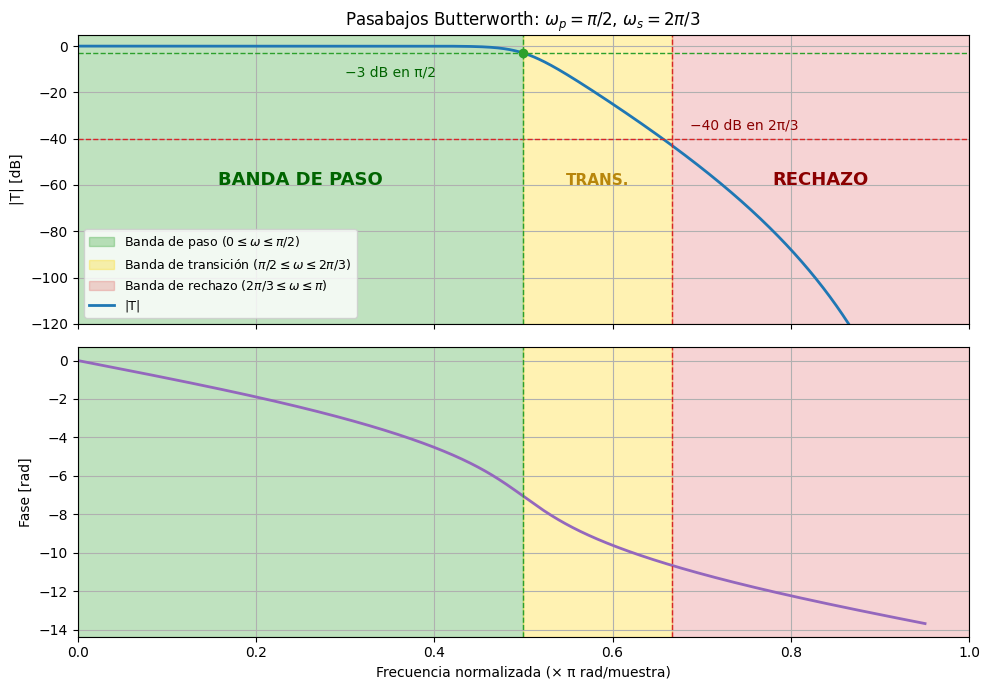

In [60]:
modulo_db = 20 * np.log10(np.abs(H) + 1e-15)
fase = np.unwrap(np.angle(H))
fase[modulo_db < -200] = np.nan   # donde |T| ≈ 0 el ángulo es ruido numérico

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Módulo
ax1.axvspan(0, wp, color='tab:green', alpha=0.30, label=r'Banda de paso ($0 \leq \omega \leq \pi/2$)')
ax1.axvspan(wp, ws, color='gold', alpha=0.30, label=r'Banda de transición ($\pi/2 \leq \omega \leq 2\pi/3$)')
ax1.axvspan(ws, 1, color='tab:red', alpha=0.20, label=r'Banda de rechazo ($2\pi/3 \leq \omega \leq \pi$)')
ax1.text(wp / 2, -60, 'BANDA DE PASO', ha='center', fontsize=13, fontweight='bold', color='darkgreen')
ax1.text((wp + ws) / 2, -60, 'TRANS.', ha='center', fontsize=11, fontweight='bold', color='darkgoldenrod')
ax1.text((ws + 1) / 2, -60, 'RECHAZO', ha='center', fontsize=13, fontweight='bold', color='darkred')
ax1.plot(w, modulo_db, color='tab:blue', lw=2, label='|T|')
ax1.axhline(-gpass, color='tab:green', ls='--', lw=1)
ax1.axhline(-gstop, color='tab:red', ls='--', lw=1)
ax1.axvline(wp, color='tab:green', ls='--', lw=1)
ax1.axvline(ws, color='tab:red', ls='--', lw=1)
ax1.plot(wp, -gpass, 'o', color='tab:green')
ax1.annotate(f'−{gpass} dB en π/2', xy=(wp, -gpass), xytext=(wp - 0.2, -gpass - 10), color='darkgreen')
ax1.annotate(f'−{gstop} dB en 2π/3', xy=(ws, -gstop), xytext=(ws + 0.02, -gstop + 4), color='darkred')
ax1.set_ylim(-120, 5)
ax1.set_ylabel('|T| [dB]')
ax1.set_title(r'Pasabajos Butterworth: $\omega_p = \pi/2$, $\omega_s = 2\pi/3$')
ax1.legend(loc='lower left', fontsize=9)
ax1.grid(True)

# Fase
ax2.axvspan(0, wp, color='tab:green', alpha=0.30)
ax2.axvspan(wp, ws, color='gold', alpha=0.30)
ax2.axvspan(ws, 1, color='tab:red', alpha=0.20)
ax2.plot(w, fase, color='tab:purple', lw=2)
ax2.axvline(wp, color='tab:green', ls='--', lw=1)
ax2.axvline(ws, color='tab:red', ls='--', lw=1)
ax2.set_ylabel('Fase [rad]')
ax2.set_xlabel('Frecuencia normalizada (× π rad/muestra)')
ax2.set_xlim(0, 1)
ax2.grid(True)

plt.tight_layout()
plt.show()